# Operational Reporting

**Operational reports** are produced on a schedule (daily, weekly, monthly) for people who run the business: the same KPIs, the same layout, every period. Their value comes from **reliability**: correct definitions, comparisons, alerts when something changes, and automatic delivery.

**After this lesson you can:**

1. Write KPI definitions with formula, grain, owner and alert thresholds.
2. Compute KPIs per period with comparisons to the previous period.
3. Detect threshold breaches and flag them automatically.
4. Generate a self-contained HTML report and schedule it.

**Data:** NYC yellow taxi trips, January and February 2024, in complete weeks (Monday to Sunday).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

trips = pd.concat([load_month("2024-01"), load_month("2024-02")], ignore_index=True)
trips["week"] = trips["tpep_pickup_datetime"].dt.to_period("W-SUN").dt.start_time      # weeks start on Monday
trips = trips[(trips["week"] >= "2024-01-01") & (trips["week"] <= "2024-02-19")]        # complete weeks only
print(f"{len(trips):,} trips in {trips['week'].nunique()} complete weeks")

5,315,987 trips in 8 complete weeks


## 1. KPI Definitions

A KPI definition is a **contract**: everybody who reads the report must understand the number in the same way. Write it down in code, next to the calculation.

In [2]:
KPIS = {
    "trips":        {"label": "Trips", "fmt": "{:,.0f}", "good": "up", "alert_pct": 10,
                     "definition": "count of cleaned trips with pickup in the week"},
    "revenue":      {"label": "Revenue (USD)", "fmt": "${:,.0f}", "good": "up", "alert_pct": 10,
                     "definition": "sum of total_amount (fare, surcharges, tolls, tips)"},
    "avg_fare":     {"label": "Average fare (USD)", "fmt": "${:.2f}", "good": "none", "alert_pct": 5,
                     "definition": "mean of fare_amount"},
    "card_tip_pct": {"label": "Card tip rate", "fmt": "{:.1f}%", "good": "up", "alert_pct": 5,
                     "definition": "sum of tips / sum of fares, card trips only (cash tips are not recorded)"},
    "airport_share": {"label": "Airport share", "fmt": "{:.1f}%", "good": "none", "alert_pct": 10,
                      "definition": "share of trips starting or ending at JFK (132) or LaGuardia (138)"},
}

def compute_kpis(df: pd.DataFrame) -> pd.Series:
    card = df[df["payment_type"] == 1]
    airport = df["PULocationID"].isin([132, 138]) | df["DOLocationID"].isin([132, 138])
    return pd.Series({"trips": len(df), "revenue": df["total_amount"].sum(), "avg_fare": df["fare_amount"].mean(),
                      "card_tip_pct": 100 * card["tip_amount"].sum() / card["fare_amount"].sum(),
                      "airport_share": 100 * airport.mean()})

weekly = trips.groupby("week").apply(compute_kpis, include_groups=False)
weekly.round(2)

,trips,revenue,avg_fare,card_tip_pct,airport_share
week,,,,,
2024-01-01,584602.0,16574650.00,19.49,22.20,11.49
2024-01-08,652836.0,17701749.57,18.25,22.73,9.47
2024-01-15,654128.0,17706915.24,18.28,22.76,9.59
2024-01-22,685254.0,18455563.93,18.12,22.71,8.43
2024-01-29,678783.0,18181015.27,17.96,22.74,8.34
2024-02-05,700350.0,19104386.79,18.37,22.66,8.55
2024-02-12,679348.0,18206610.98,18.11,22.73,8.37
2024-02-19,680686.0,18699554.44,18.64,22.47,9.82


## 2. Comparisons and Alerts

Each KPI is compared with the **previous week** and with the **average of the previous four weeks** (a more stable baseline). An alert fires when the change against the baseline exceeds the KPI's threshold.

In [3]:
def report_table(weekly: pd.DataFrame, week: pd.Timestamp) -> pd.DataFrame:
    i = weekly.index.get_loc(week)
    cur, prev = weekly.iloc[i], weekly.iloc[i - 1]
    base = weekly.iloc[max(0, i - 4):i].mean()
    rows = []
    for key, spec in KPIS.items():
        vs_base = 100 * (cur[key] / base[key] - 1)
        alert = abs(vs_base) >= spec["alert_pct"]
        rows.append({"KPI": spec["label"], "This week": spec["fmt"].format(cur[key]),
                     "vs last week": f"{100 * (cur[key] / prev[key] - 1):+.1f}%",
                     "vs 4-week avg": f"{vs_base:+.1f}%", "Alert": "ALERT" if alert else ""})
    return pd.DataFrame(rows)

weeks = weekly.index
for w in weeks[4:]:
    t = report_table(weekly, w)
    alerts = t.loc[t["Alert"] != "", "KPI"].tolist()
    print(f"week of {w:%d %b}: {'alerts: ' + ', '.join(alerts) if alerts else 'no alerts'}")

week of 29 Jan: alerts: Airport share
week of 05 Feb: no alerts
week of 12 Feb: no alerts
week of 19 Feb: alerts: Airport share


## 3. Generate the Report

The report is one **self-contained HTML file**: KPI table, trend charts embedded as images (base64), definitions and a footer with data source and run time. It can be e-mailed, stored or published without other files.

In [4]:
import base64
import datetime as dt
import io
import tempfile

def chart_png(weekly: pd.DataFrame, week: pd.Timestamp) -> str:
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
    for ax, key in zip(axes, ["trips", "revenue", "card_tip_pct"]):
        s = weekly.loc[:week, key]
        ax.plot(s.index, s.values, marker="o", color="#4E79A7")
        ax.scatter([week], [s.iloc[-1]], color="#E15759", zorder=3, s=50)
        ax.set_title(KPIS[key]["label"], fontsize=10)
        ax.tick_params(axis="x", rotation=30, labelsize=7)
    plt.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

def build_report(weekly: pd.DataFrame, week: pd.Timestamp) -> str:
    table = report_table(weekly, week)
    styled = table.style.hide(axis="index").map(lambda v: "color:#C62828;font-weight:bold" if v == "ALERT" else "", subset=["Alert"])
    defs = "".join(f"<li><b>{s['label']}</b>: {s['definition']} (alert at ±{s['alert_pct']}% vs 4-week average)</li>"
                   for s in KPIS.values())
    return f"""<html><head><meta charset="utf-8"><title>Weekly taxi report {week:%Y-%m-%d}</title>
<style>body{{font-family:Arial, sans-serif;max-width:900px;margin:auto}} td,th{{padding:4px 10px}}</style></head><body>
<h2>NYC Yellow Taxi - weekly operations report</h2><p>Week of {week:%A %d %B %Y}</p>
{styled.to_html()}
<img alt="Weekly trends of trips, revenue and card tip rate" src="data:image/png;base64,{chart_png(weekly, week)}" style="width:100%">
<h4>Definitions</h4><ul>{defs}</ul>
<p style="color:#777;font-size:12px">Source: NYC TLC trip records (cleaned). Generated {dt.datetime.now():%Y-%m-%d %H:%M}.</p>
</body></html>"""

out_dir = Path(tempfile.mkdtemp())
week = weeks[-1]
html = build_report(weekly, week)
path = out_dir / f"taxi_weekly_{week:%Y-%m-%d}.html"
path.write_text(html, encoding="utf-8")
print(f"report written: {path.name}, {path.stat().st_size / 1024:.0f} KiB")
report_table(weekly, week)

report written: taxi_weekly_2024-02-19.html, 83 KiB


,KPI,This week,vs last week,vs 4-week avg,Alert
0,Trips,"680,686",+0.2%,-0.8%,
1,Revenue (USD),"$18,699,554",+2.7%,+1.2%,
2,Average fare (USD),$18.64,+2.9%,+2.8%,
3,Card tip rate,22.5%,-1.2%,-1.1%,
4,Airport share,9.8%,+17.3%,+16.6%,ALERT


KPI,This week,vs last week,vs 4-week avg,Alert
Trips,"680,686",+0.2%,-0.8%,
Revenue (USD),"$18,699,554",+2.7%,+1.2%,
Average fare (USD),$18.64,+2.9%,+2.8%,
Card tip rate,22.5%,-1.2%,-1.1%,
Airport share,9.8%,+17.3%,+16.6%,ALERT

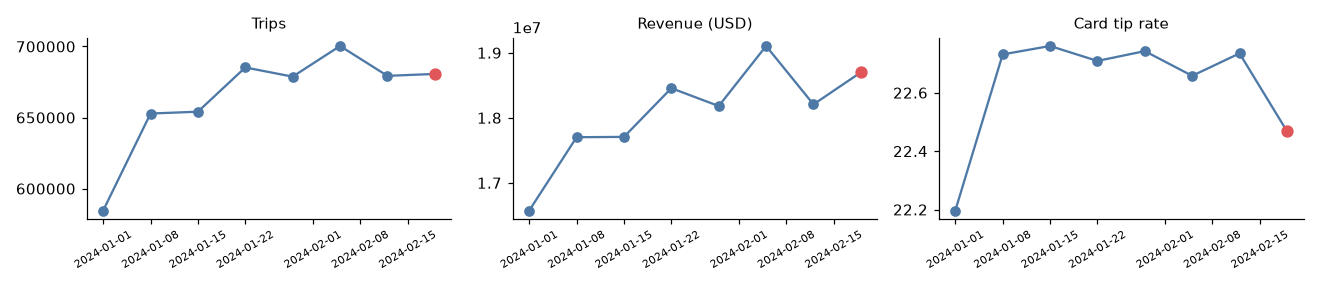

In [5]:
from IPython.display import HTML, display

display(HTML(html[html.index("<h2>"):html.index("<h4>")]))

## 4. Schedule and Deliver

| Option | How |
| :--- | :--- |
| cron (Linux/WSL) | `0 7 * * 1  cd /repo && .venv/bin/python reports/weekly.py` (Mondays at 07:00) |
| Windows Task Scheduler | the same command as a scheduled task |
| orchestrator | an Airflow or Dagster job with retries and alerts (M11) |
| BI subscriptions | Tableau, Power BI and Superset can e-mail a dashboard snapshot on a schedule |

Make the job **idempotent** (running it twice for the same week gives the same file), log every run, and send an alert when the job fails, not only when a KPI breaks its threshold.

## 5. Refresh Cadence

| Report | Cadence | Typical latency |
| :--- | :--- | :--- |
| executive KPIs | weekly / monthly | data up to the previous day |
| operations | daily | data up to a few hours ago |
| live monitoring | minutes | streaming (M12) |

Choose the cadence by the speed of the **decisions**, not the speed of the data: a weekly staffing decision does not need a real-time dashboard.

*Insight: An operational report is a product: fixed definitions, stable layout, comparisons with a baseline, automatic alerts, and an automated, monitored schedule. Readers trust it because it never surprises them except when the business does.*

## Real-World Use Case or Analogy

An operational report is like a **pilot's pre-flight checklist**: the same items in the same order every time, so that any deviation stands out immediately. Its power comes from repetition, not from novelty.

Logistics companies send daily delivery reports, retailers weekly sales reports by store, hospitals daily bed-occupancy reports. Alerts on thresholds turn the report from something people must read into something that tells them when to look.